In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')

df = pd.read_csv(r'C:\Trend Mart Analysis\retail_sales_data.csv')
df.shape

(6417, 25)

# TrendMart Sales Analysis

**Summary:** Analyzed 3 years of order data (2022-2024, ~6,200 orders) to identify where the business is losing money and where it should focus to grow. Key findings:

1. **Electronics profit margin collapsed from 43% to 25% in 2024** due to rising supplier costs that weren't reflected in selling prices, an estimated $35,000 in lost profit in one year.
2. **Clothing orders acquired through Social Media return at 33.9%**, more than 3x the company average, confirmed not to be a product quality issue (ratings for Clothing remain high), pointing to a sizing/expectations problem specific to that channel.
3. Revenue is flat overall (2022-2024) and concentrated in 2 regions (West, South, ~76% combined) and 2 months (Nov/Dec, ~30% of each year).
4. Discounting shows no evidence of driving incremental sales, margin falls steadily with discount depth while average order size shrinks.

Full data cleaning process, exploratory analysis, and supporting evidence for each findings follow below.

In [2]:
df.head(10)

,Order_ID,Order_Date,Ship_Date,Customer_ID,Customer_Name,Email,Age,Gender,Customer_Segment,City,State,Country,Product_ID,Product_Name,Category,Sub_Category,Unit_Price,Cost_Price,Quantity,Discount_Percent,Shipping_Cost,Payment_Method,Marketing_Channel,Order_Status,Review_Rating
0,ORD503560,2022-08-05,2022-08-13,C21515,Melanie Jones,jliu@example.org,NaN,MALE,Home Office,Columbus,OH,United States,P10015,Smart Essential 259,Electronics,Smart Home,197.75,105.72,1,0.05,9.61,Gift Card,Referral,Delivered,NaN
1,ORD503427,2024-01-08,2024-01-11,C21541,Chloe Freeman,woodjuan@example.net,23.0,male,Consumer,Portland,OR,USA,P10109,Non-Fiction Original 690,Books,Non-Fiction,16.73,8.66,2,0.00,20.78,Bank Transfer,Affiliate,Delivered,1.0
2,ORD505784,"May 09, 2023",NaN,C20107,Derek Thomas,martinkyle@example.net,40.0,female,Consumer,Dallas,TX,USA,P10067,Small Sport 868,HOME & KITCHEN,Small Appliances,67.55,34.06,2,NaN,NaN,Credit Card,Organic Search,Processing,NaN
3,ORD502454,2024-05-06,2024-05-14,C21095,Eric Graham,larry82_at_example.org,30.0,Unknown,Consumer,Chicago,IL,US,P10051,Furniture Sport 651,Home & Kitchen,Furniture,323.28,169.21,1,0.05,17.05,Credit Card,Paid Search,Delivered,NaN
4,ORD503946,12/03/2023,2023-03-20,C20823,George Le,zwilson@example.net,44.0,M,Corporate,Boston,Massachusetts,USA,P10001,Headphones Pro 859,Electronics,Headphones,365.70,NaN,1,0.00,24.26,Credit Card,Email Marketing,Returned,NaN
5,ORD502300,10/05/2022,2022-10-12,C20347,Robin Wheeler,rodriguezjohn@example.net,34.0,F,Consumer,Phoenix,AZ,USA,P10060,Storage Compact 710,Home & Kitchen,Storage,122.44,69.80,1,0.00,17.09,Gift Card,Organic Search,Delivered,2.0
6,ORD502229,2023-12-17,2023-12-20,C20526,Sarah Rivera,xmoran@example.net,47.0,FEMALE,Home Office,Raleigh,North Carolina,United States,P10008,Laptops Sport 716,Electronics,Laptops,835.69,428.86,1,0.15,23.74,Gift Card,Referral,Delivered,NaN
7,ORD503382,23/02/2024,NaN,C20877,Tina Daugherty,ulee@example.net,37.0,female,Home Office,Kansas City,Missouri,USA,P10057,Bedding Ultra 873,Home & Kitchen,Bedding,43.53,22.07,1,0.05,17.68,Gift Card,Social Media,Delivered,2.0
8,ORD500297,10/05/2024,2024-10-13,C21144,Kari Jones,jenniferkim@example.com,25.0,F,Consumer,Kansas City,MO,US,P10109,Non-Fiction Original 690,Books,Non-Fiction,16.72,10.16,1,0.10,24.50,Gift Card,Direct,Delivered,NaN
9,ORD506102,06/06/2023,2023-06-07,C21147,Miguel Stafford,scottwilliams@example.net,37.0,male,Consumer,Phoenix,AZ,USA,P10052,Furniture Essential 864,Home & Kitchen,Furniture,255.07,145.22,3,0.00,24.62,Gift Card,Paid Search,Delivered,5.0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6417 entries, 0 to 6416
Data columns (total 25 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Order_ID           6417 non-null   object 
 1   Order_Date         6417 non-null   object 
 2   Ship_Date          5972 non-null   object 
 3   Customer_ID        6417 non-null   object 
 4   Customer_Name      6417 non-null   object 
 5   Email              5905 non-null   object 
 6   Age                6031 non-null   float64
 7   Gender             6255 non-null   object 
 8   Customer_Segment   6417 non-null   object 
 9   City               6417 non-null   object 
 10  State              6417 non-null   object 
 11  Country            6417 non-null   object 
 12  Product_ID         6417 non-null   object 
 13  Product_Name       6417 non-null   object 
 14  Category           6417 non-null   object 
 15  Sub_Category       6417 non-null   object 
 16  Unit_Price         6417 

In [4]:
df.isna().sum().sort_values(ascending = False)

Review_Rating        2686
Discount_Percent      901
Email                 512
Ship_Date             445
Age                   386
Shipping_Cost         385
Cost_Price            324
Marketing_Channel     174
Gender                162
Sub_Category            0
Order_Status            0
Payment_Method          0
Quantity                0
Unit_Price              0
Order_ID                0
Category                0
Product_Name            0
Order_Date              0
Country                 0
State                   0
City                    0
Customer_Segment        0
Customer_Name           0
Customer_ID             0
Product_ID              0
dtype: int64

In [5]:
df.duplicated().sum()

217

In [6]:
df.describe(include='all')

,Order_ID,Order_Date,Ship_Date,Customer_ID,Customer_Name,Email,Age,Gender,Customer_Segment,City,State,Country,Product_ID,Product_Name,Category,Sub_Category,Unit_Price,Cost_Price,Quantity,Discount_Percent,Shipping_Cost,Payment_Method,Marketing_Channel,Order_Status,Review_Rating
count,6417,6417,5972,6417,6417,5905,6031.000000,6255,6417,6417,6417,6417,6417,6417,6417,6417,6417.000000,6093.000000,6417.000000,5516.000000,6032.000000,6417,6243,6417,3731.000000
unique,6200,2550,1094,1567,1784,1707,NaN,10,3,60,40,5,137,248,21,32,NaN,NaN,NaN,NaN,NaN,5,8,5,NaN
top,ORD504944,2022-11-02,2022-01-01,C20001,Anthony Brown,davisjesse@example.net,NaN,FEMALE,Consumer,Portland,CA,USA,P10042,Storage Compact 710,Clothing,Activewear,NaN,NaN,NaN,NaN,NaN,Gift Card,Organic Search,Delivered,NaN
freq,2,17,65,13,14,12,NaN,818,3950,289,855,3504,65,95,1029,317,NaN,NaN,NaN,NaN,NaN,1330,1407,4396,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,37.046924,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,146.919877,82.794641,1.621630,0.383267,15.353231,NaN,NaN,NaN,3.907531
std,NaN,NaN,NaN,NaN,NaN,NaN,11.453154,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,185.512730,108.274545,2.961287,2.305587,7.518396,NaN,NaN,NaN,1.151185
min,NaN,NaN,NaN,NaN,NaN,NaN,-5.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,-910.290000,2.950000,0.000000,0.000000,3.000000,NaN,NaN,NaN,-1.000000
25%,NaN,NaN,NaN,NaN,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,36.060000,19.280000,1.000000,0.000000,9.380000,NaN,NaN,NaN,3.000000
50%,NaN,NaN,NaN,NaN,NaN,NaN,37.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,72.300000,38.850000,1.000000,0.000000,15.120000,NaN,NaN,NaN,4.000000
75%,NaN,NaN,NaN,NaN,NaN,NaN,45.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,191.470000,104.440000,2.000000,0.100000,20.580000,NaN,NaN,NaN,5.000000


In [7]:

# 2. Data Cleaning


In [8]:
# Dropping duplicates and changing data types along with replacing fake dates with NaT Values in Ship Date.

df = pd.read_csv(r'C:\Trend Mart Analysis\retail_sales_data.csv')
df = df.drop_duplicates().reset_index(drop=True)

def smart_parse_date(date_str):
    if '/' in date_str:
        first, second = date_str.split('/')[0], date_str.split('/')[1]
        first, second = int(first), int(second)
        if first > 12:
            return pd.to_datetime(date_str, dayfirst=True)
        elif second > 12:
            return pd.to_datetime(date_str, dayfirst=False)
        else:
            return pd.to_datetime(date_str, dayfirst=True)
    else:
        return pd.to_datetime(date_str, format='mixed')

df['Order_Date'] = df['Order_Date'].apply(smart_parse_date)
df['Ship_Date'] = pd.to_datetime(df['Ship_Date'], format='mixed', errors='coerce')

df[['Order_Date', 'Ship_Date']].dtypes

Order_Date    datetime64[ns]
Ship_Date     datetime64[ns]
dtype: object

In [9]:
invalid_ship = df['Ship_Date'] < df['Order_Date']
invalid_ship.sum()

140

In [10]:
placeholder_mask = df['Ship_Date'] == pd.Timestamp('2022-01-01')
df.loc[placeholder_mask, 'Ship_Date'] = pd.NaT
df['Ship_Date'].isna().sum()

494

In [11]:
# Standardizing Gender Column

df['Gender'].value_counts(dropna=False)

Gender
FEMALE     789
Female     761
male       734
female     734
F          726
MALE       721
M          721
Male       704
NaN        160
Unknown     88
-           62
Name: count, dtype: int64

In [12]:
df['Gender'] = df['Gender'].str.strip().str.upper()
df['Gender'] = df['Gender'].replace({
    'MALE': 'Male',
    'M': 'Male',
    'FEMALE': 'Female',
    'F': 'Female',
    'UNKNOWN': np.nan,
    '-': np.nan
})

In [13]:
df['Gender'].dtype

dtype('O')

In [14]:
df['Gender'].value_counts(dropna=False)

Gender
Female    3010
Male      2880
NaN        310
Name: count, dtype: int64

In [15]:
# Standardizing Category Column

df['Category'].value_counts(dropna=False)

Category
Clothing                  999
Home & Kitchen            952
Electronics               810
Sports & Outdoors         695
Books                     695
Beauty & Personal Care    684
Toys & Games              656
home & kitchen             66
CLOTHING                   65
clothing                   58
HOME & KITCHEN             55
SPORTS & OUTDOORS          53
ELECTRONICS                52
TOYS & GAMES               50
electronics                48
beauty & personal care     47
sports & outdoors          46
BEAUTY & PERSONAL CARE     44
BOOKS                      44
books                      43
toys & games               38
Name: count, dtype: int64

In [16]:
df['Category'] = df['Category'].str.strip().str.title()
df['Category'].value_counts(dropna=False)

Category
Clothing                  1122
Home & Kitchen            1073
Electronics                910
Sports & Outdoors          794
Books                      782
Beauty & Personal Care     775
Toys & Games               744
Name: count, dtype: int64

In [17]:
# Standardizing Country Column

df['Country'].value_counts(dropna=False)

Country
USA              3395
United States    1379
US                816
usa               357
U.S.A.            253
Name: count, dtype: int64

In [18]:
df['Country'] = df['Country'].replace({
    'United States': 'USA',
    'US': 'USA',
    'usa': 'USA',
    'U.S.A.': 'USA'
})
df['Country'].value_counts(dropna=False)

Country
USA    6200
Name: count, dtype: int64

In [19]:
# Standardizing State Column

df['State'].value_counts(dropna=False)

State
CA                828
TX                744
OH                400
FL                379
NC                311
OR                254
MA                225
IL                223
NV                220
TN                207
GA                205
MO                190
MN                183
MI                177
CO                166
AZ                166
WA                152
NY                150
UT                146
PA                130
California        123
Texas              87
Ohio               67
Florida            56
North Carolina     52
Oregon             35
Utah               31
Nevada             30
Arizona            27
Illinois           27
Minnesota          26
Massachusetts      24
New York           23
Missouri           23
Washington         22
Georgia            21
Tennessee          21
Michigan           17
Colorado           17
Pennsylvania       15
Name: count, dtype: int64

In [20]:
state_map = {
    'California': 'CA', 'Texas': 'TX', 'Ohio': 'OH', 'Florida': 'FL',
    'North Carolina': 'NC', 'Oregon': 'OR', 'Massachusetts': 'MA',
    'Illinois': 'IL', 'Nevada': 'NV', 'Tennessee': 'TN', 'Georgia': 'GA',
    'Missouri': 'MO', 'Minnesota': 'MN', 'Michigan': 'MI', 'Colorado': 'CO',
    'Arizona': 'AZ', 'Washington': 'WA', 'New York': 'NY', 'Utah': 'UT',
    'Pennsylvania': 'PA'
}
df['State'] = df['State'].replace(state_map)
df['State'].value_counts(dropna=False)

State
CA    951
TX    831
OH    467
FL    435
NC    363
OR    289
IL    250
NV    250
MA    249
TN    228
GA    226
MO    213
MN    209
MI    194
AZ    193
CO    183
UT    177
WA    174
NY    173
PA    145
Name: count, dtype: int64

In [21]:
df

,Order_ID,Order_Date,Ship_Date,Customer_ID,Customer_Name,Email,Age,Gender,Customer_Segment,City,State,Country,Product_ID,Product_Name,Category,Sub_Category,Unit_Price,Cost_Price,Quantity,Discount_Percent,Shipping_Cost,Payment_Method,Marketing_Channel,Order_Status,Review_Rating
0,ORD503560,2022-08-05,2022-08-13,C21515,Melanie Jones,jliu@example.org,NaN,Male,Home Office,Columbus,OH,USA,P10015,Smart Essential 259,Electronics,Smart Home,197.75,105.72,1,0.05,9.61,Gift Card,Referral,Delivered,NaN
1,ORD503427,2024-01-08,2024-01-11,C21541,Chloe Freeman,woodjuan@example.net,23.0,Male,Consumer,Portland,OR,USA,P10109,Non-Fiction Original 690,Books,Non-Fiction,16.73,8.66,2,0.00,20.78,Bank Transfer,Affiliate,Delivered,1.0
2,ORD505784,2023-05-09,NaT,C20107,Derek Thomas,martinkyle@example.net,40.0,Female,Consumer,Dallas,TX,USA,P10067,Small Sport 868,Home & Kitchen,Small Appliances,67.55,34.06,2,NaN,NaN,Credit Card,Organic Search,Processing,NaN
3,ORD502454,2024-05-06,2024-05-14,C21095,Eric Graham,larry82_at_example.org,30.0,NaN,Consumer,Chicago,IL,USA,P10051,Furniture Sport 651,Home & Kitchen,Furniture,323.28,169.21,1,0.05,17.05,Credit Card,Paid Search,Delivered,NaN
4,ORD503946,2023-03-12,2023-03-20,C20823,George Le,zwilson@example.net,44.0,Male,Corporate,Boston,MA,USA,P10001,Headphones Pro 859,Electronics,Headphones,365.70,NaN,1,0.00,24.26,Credit Card,Email Marketing,Returned,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6195,ORD503773,2023-03-03,2023-03-06,C21486,Allison Casey,amandadalton@example.net,21.0,Female,Consumer,Denver,CO,USA,P10029,Women's Essential 181,Clothing,Women's Apparel,91.48,48.01,2,0.00,9.54,PayPal,Social Media,Delivered,NaN
6196,ORD505192,2023-09-14,2023-09-20,C20466,Kara Jackson,mthomas@example.net,34.0,Male,Consumer,New York,NY,USA,P10077,Cycling Classic 652,Sports & Outdoors,Cycling,333.86,158.78,1,0.00,8.57,Credit Card,Social Media,Delivered,3.0
6197,ORD505227,2023-06-13,2023-06-19,C20835,Justin Lee,montgomerymichelle@example.net,36.0,Female,Consumer,San Diego,CA,USA,P10078,Cycling Sport 100,Sports & Outdoors,Cycling,36.70,17.91,1,20.00,3.43,Credit Card,Organic Search,Delivered,NaN
6198,ORD505391,2022-08-11,2022-08-18,C20326,Amanda Mcfarland,alexis39@example.org,36.0,Male,Consumer,New York,NY,USA,P10021,Men's Pro 847,Clothing,Men's Apparel,96.29,47.45,1,0.15,13.24,Bank Transfer,Organic Search,Delivered,NaN


In [22]:
# Fixing Age Outliers

df[(df['Age'] < 18) | (df['Age'] > 100)]['Age'].value_counts(dropna=False)

Age
-5.0      4
 121.0    3
 150.0    1
Name: count, dtype: int64

In [23]:
df.loc[(df['Age'] < 18) | (df['Age'] > 100), 'Age'] = np.nan
df['Age'].isna().sum()

380

In [24]:
# Fix Unit Price and Quantity Errors

df[df['Unit_Price'] <= 0][['Order_ID', 'Product_Name', 'Unit_Price', 'Quantity']]

,Order_ID,Product_Name,Unit_Price,Quantity
110,ORD504223,Cameras Original 384,-910.29,1
183,ORD506144,Cameras Pro 877,-695.22,1
520,ORD501222,Cycling Ultra 471,-351.08,2
691,ORD505633,Storage Compact 710,-126.97,5
745,ORD501972,Footwear Essential 818,-154.26,2
812,ORD503675,Puzzles Compact 597,-34.56,1
998,ORD500642,Team Premium 159,-275.46,2
1022,ORD505488,Women's Essential 181,-93.62,1
1208,ORD501384,Footwear Essential 818,-147.74,1
1261,ORD506049,Fragrances Original 325,-8.03,4


In [25]:
df['Unit_Price'] = df['Unit_Price'].abs()
(df['Unit_Price'] <= 0).sum()

0

In [26]:
(df['Quantity'] == 0).sum()

31

In [27]:
df[df['Quantity'] > 10][['Order_ID', 'Product_Name', 'Unit_Price', 'Quantity']].sort_values('Quantity', ascending=False)

,Order_ID,Product_Name,Unit_Price,Quantity
2842,ORD504280,Men's Pro 847,96.66,120
926,ORD501057,Board Sport 200,35.68,80
2051,ORD500721,Laptops Pro 674,551.03,80
2080,ORD502100,Cookware Original 997,219.96,80
3257,ORD500821,Furniture Classic 352,88.32,80
4173,ORD500708,Team Ultra 849,143.47,80


In [28]:
df.loc[(df['Quantity'] == 0) | (df['Quantity'] > 10), 'Quantity'] = np.nan
df['Quantity'].isna().sum()

37

In [29]:
# Fixing Discount Percent

(df['Discount_Percent'] > 1).sum()

130

In [30]:
df[df['Discount_Percent'] > 1]['Discount_Percent'].value_counts().sort_index()

Discount_Percent
5.0     37
10.0    32
15.0    22
20.0    26
25.0     9
30.0     4
Name: count, dtype: int64

In [31]:
df.loc[df['Discount_Percent'] > 1, 'Discount_Percent'] = df.loc[df['Discount_Percent'] > 1, 'Discount_Percent'] / 100
df['Discount_Percent'].describe()

count    5332.000000
mean        0.061093
std         0.078471
min         0.000000
25%         0.000000
50%         0.000000
75%         0.100000
max         0.300000
Name: Discount_Percent, dtype: float64

In [32]:
# Fixing Invalid Review Rating Values

df.loc[(df['Review_Rating'] < 1) | (df['Review_Rating'] > 5), 'Review_Rating'] = np.nan
df['Review_Rating'].describe()

count    3594.000000
mean        3.913745
std         1.140219
min         1.000000
25%         3.000000
50%         4.000000
75%         5.000000
max         5.000000
Name: Review_Rating, dtype: float64

In [33]:
df


,Order_ID,Order_Date,Ship_Date,Customer_ID,Customer_Name,Email,Age,Gender,Customer_Segment,City,State,Country,Product_ID,Product_Name,Category,Sub_Category,Unit_Price,Cost_Price,Quantity,Discount_Percent,Shipping_Cost,Payment_Method,Marketing_Channel,Order_Status,Review_Rating
0,ORD503560,2022-08-05,2022-08-13,C21515,Melanie Jones,jliu@example.org,NaN,Male,Home Office,Columbus,OH,USA,P10015,Smart Essential 259,Electronics,Smart Home,197.75,105.72,1.0,0.05,9.61,Gift Card,Referral,Delivered,NaN
1,ORD503427,2024-01-08,2024-01-11,C21541,Chloe Freeman,woodjuan@example.net,23.0,Male,Consumer,Portland,OR,USA,P10109,Non-Fiction Original 690,Books,Non-Fiction,16.73,8.66,2.0,0.00,20.78,Bank Transfer,Affiliate,Delivered,1.0
2,ORD505784,2023-05-09,NaT,C20107,Derek Thomas,martinkyle@example.net,40.0,Female,Consumer,Dallas,TX,USA,P10067,Small Sport 868,Home & Kitchen,Small Appliances,67.55,34.06,2.0,NaN,NaN,Credit Card,Organic Search,Processing,NaN
3,ORD502454,2024-05-06,2024-05-14,C21095,Eric Graham,larry82_at_example.org,30.0,NaN,Consumer,Chicago,IL,USA,P10051,Furniture Sport 651,Home & Kitchen,Furniture,323.28,169.21,1.0,0.05,17.05,Credit Card,Paid Search,Delivered,NaN
4,ORD503946,2023-03-12,2023-03-20,C20823,George Le,zwilson@example.net,44.0,Male,Corporate,Boston,MA,USA,P10001,Headphones Pro 859,Electronics,Headphones,365.70,NaN,1.0,0.00,24.26,Credit Card,Email Marketing,Returned,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6195,ORD503773,2023-03-03,2023-03-06,C21486,Allison Casey,amandadalton@example.net,21.0,Female,Consumer,Denver,CO,USA,P10029,Women's Essential 181,Clothing,Women's Apparel,91.48,48.01,2.0,0.00,9.54,PayPal,Social Media,Delivered,NaN
6196,ORD505192,2023-09-14,2023-09-20,C20466,Kara Jackson,mthomas@example.net,34.0,Male,Consumer,New York,NY,USA,P10077,Cycling Classic 652,Sports & Outdoors,Cycling,333.86,158.78,1.0,0.00,8.57,Credit Card,Social Media,Delivered,3.0
6197,ORD505227,2023-06-13,2023-06-19,C20835,Justin Lee,montgomerymichelle@example.net,36.0,Female,Consumer,San Diego,CA,USA,P10078,Cycling Sport 100,Sports & Outdoors,Cycling,36.70,17.91,1.0,0.20,3.43,Credit Card,Organic Search,Delivered,NaN
6198,ORD505391,2022-08-11,2022-08-18,C20326,Amanda Mcfarland,alexis39@example.org,36.0,Male,Consumer,New York,NY,USA,P10021,Men's Pro 847,Clothing,Men's Apparel,96.29,47.45,1.0,0.15,13.24,Bank Transfer,Organic Search,Delivered,NaN


In [34]:
# Feature Engineering
# Handling Missing Discount Percent

df['Discount_Missing'] = df['Discount_Percent'].isna()
df['Discount_Percent'] = df['Discount_Percent'].fillna(0)

df['Discount_Missing'].sum()

868

In [35]:
# Creating Revenue

df['Revenue'] = df['Unit_Price'] * df['Quantity'] * (1 - df['Discount_Percent'])

df['Revenue'].isna().sum()
df['Revenue'].describe()

count    6163.00000
mean      219.50477
std       338.30917
min         5.51600
25%        40.68500
50%        92.93000
75%       263.30000
max      3815.90000
Name: Revenue, dtype: float64

In [36]:
# Creating Total Cost, Profit, Profit Margin%

df['Total_Cost'] = df['Cost_Price'] * df['Quantity']
df['Profit'] = df['Revenue'] - df['Total_Cost']
df['Profit_Margin_%'] = (df['Profit'] / df['Revenue']) * 100

df[['Revenue', 'Total_Cost', 'Profit', 'Profit_Margin_%']].describe()

,Revenue,Total_Cost,Profit,Profit_Margin_%
count,6163.00000,5854.000000,5854.000000,5854.000000
mean,219.50477,128.832610,89.622095,42.269194
std,338.30917,209.171517,137.884236,8.319027
min,5.51600,2.950000,-25.928000,-9.572049
25%,40.68500,23.010000,17.163250,38.398095
50%,92.93000,52.625000,39.045000,43.203734
75%,263.30000,145.440000,105.353500,48.443373
max,3815.90000,2658.280000,1758.100000,54.994325


In [37]:
df

,Order_ID,Order_Date,Ship_Date,Customer_ID,Customer_Name,Email,Age,Gender,Customer_Segment,City,State,Country,Product_ID,Product_Name,Category,Sub_Category,Unit_Price,Cost_Price,Quantity,Discount_Percent,Shipping_Cost,Payment_Method,Marketing_Channel,Order_Status,Review_Rating,Discount_Missing,Revenue,Total_Cost,Profit,Profit_Margin_%
0,ORD503560,2022-08-05,2022-08-13,C21515,Melanie Jones,jliu@example.org,NaN,Male,Home Office,Columbus,OH,USA,P10015,Smart Essential 259,Electronics,Smart Home,197.75,105.72,1.0,0.05,9.61,Gift Card,Referral,Delivered,NaN,False,187.8625,105.72,82.1425,43.724799
1,ORD503427,2024-01-08,2024-01-11,C21541,Chloe Freeman,woodjuan@example.net,23.0,Male,Consumer,Portland,OR,USA,P10109,Non-Fiction Original 690,Books,Non-Fiction,16.73,8.66,2.0,0.00,20.78,Bank Transfer,Affiliate,Delivered,1.0,False,33.4600,17.32,16.1400,48.236701
2,ORD505784,2023-05-09,NaT,C20107,Derek Thomas,martinkyle@example.net,40.0,Female,Consumer,Dallas,TX,USA,P10067,Small Sport 868,Home & Kitchen,Small Appliances,67.55,34.06,2.0,0.00,NaN,Credit Card,Organic Search,Processing,NaN,True,135.1000,68.12,66.9800,49.578090
3,ORD502454,2024-05-06,2024-05-14,C21095,Eric Graham,larry82_at_example.org,30.0,NaN,Consumer,Chicago,IL,USA,P10051,Furniture Sport 651,Home & Kitchen,Furniture,323.28,169.21,1.0,0.05,17.05,Credit Card,Paid Search,Delivered,NaN,False,307.1160,169.21,137.9060,44.903554
4,ORD503946,2023-03-12,2023-03-20,C20823,George Le,zwilson@example.net,44.0,Male,Corporate,Boston,MA,USA,P10001,Headphones Pro 859,Electronics,Headphones,365.70,NaN,1.0,0.00,24.26,Credit Card,Email Marketing,Returned,NaN,False,365.7000,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6195,ORD503773,2023-03-03,2023-03-06,C21486,Allison Casey,amandadalton@example.net,21.0,Female,Consumer,Denver,CO,USA,P10029,Women's Essential 181,Clothing,Women's Apparel,91.48,48.01,2.0,0.00,9.54,PayPal,Social Media,Delivered,NaN,False,182.9600,96.02,86.9400,47.518583
6196,ORD505192,2023-09-14,2023-09-20,C20466,Kara Jackson,mthomas@example.net,34.0,Male,Consumer,New York,NY,USA,P10077,Cycling Classic 652,Sports & Outdoors,Cycling,333.86,158.78,1.0,0.00,8.57,Credit Card,Social Media,Delivered,3.0,False,333.8600,158.78,175.0800,52.441143
6197,ORD505227,2023-06-13,2023-06-19,C20835,Justin Lee,montgomerymichelle@example.net,36.0,Female,Consumer,San Diego,CA,USA,P10078,Cycling Sport 100,Sports & Outdoors,Cycling,36.70,17.91,1.0,0.20,3.43,Credit Card,Organic Search,Delivered,NaN,False,29.3600,17.91,11.4500,38.998638
6198,ORD505391,2022-08-11,2022-08-18,C20326,Amanda Mcfarland,alexis39@example.org,36.0,Male,Consumer,New York,NY,USA,P10021,Men's Pro 847,Clothing,Men's Apparel,96.29,47.45,1.0,0.15,13.24,Bank Transfer,Organic Search,Delivered,NaN,False,81.8465,47.45,34.3965,42.025621


In [38]:
# Just a Check 

df.groupby('Category')['Cost_Price'].apply(lambda s: s.isna().mean() * 100).round(1)

Category
Beauty & Personal Care    3.9
Books                     4.7
Clothing                  5.5
Electronics               5.1
Home & Kitchen            5.3
Sports & Outdoors         5.8
Toys & Games              4.3
Name: Cost_Price, dtype: float64

In [39]:
# Creating Region From State

region_map = {
    'NY': 'Northeast', 'PA': 'Northeast', 'MA': 'Northeast',
    'IL': 'Midwest', 'OH': 'Midwest', 'MI': 'Midwest', 'MN': 'Midwest', 'MO': 'Midwest',
    'TX': 'South', 'FL': 'South', 'GA': 'South', 'NC': 'South', 'TN': 'South',
    'CA': 'West', 'AZ': 'West', 'WA': 'West', 'CO': 'West', 'OR': 'West', 'NV': 'West', 'UT': 'West'
}
df['Region'] = df['State'].map(region_map)

df['Region'].value_counts(dropna=False)

Region
West         2217
South        2083
Midwest      1333
Northeast     567
Name: count, dtype: int64

In [40]:
# Creating Date Parts From Order_Date

df['Order_Year'] = df['Order_Date'].dt.year
df['Order_Month'] = df['Order_Date'].dt.month
df['Order_Quarter'] = df['Order_Date'].dt.quarter
df['Order_YearMonth'] = df['Order_Date'].dt.to_period('M')
df['Delivery_Days'] = (df['Ship_Date'] - df['Order_Date']).dt.days

df['Order_Year'].value_counts().sort_index()
df['Delivery_Days'].describe()

count    5706.000000
mean        5.804241
std        29.036591
min      -316.000000
25%         2.000000
50%         5.000000
75%         7.000000
max       327.000000
Name: Delivery_Days, dtype: float64

In [41]:


raw = pd.read_csv(r'C:\Trend Mart Analysis\retail_sales_data.csv').drop_duplicates()
df['Order_Date_Raw'] = df['Order_ID'].map(raw.set_index('Order_ID')['Order_Date'])

def parse_with_shipdate(s, ship):
    if '/' not in s:
        return pd.to_datetime(s, format='mixed')
    a, b = int(s.split('/')[0]), int(s.split('/')[1])
    if a > 12:
        return pd.to_datetime(s, dayfirst=True)
    if b > 12:
        return pd.to_datetime(s, dayfirst=False)
    day_first = pd.to_datetime(s, dayfirst=True)
    month_first = pd.to_datetime(s, dayfirst=False)
    if pd.isna(ship):
        return day_first
    ok_d = 0 <= (ship - day_first).days <= 14
    ok_m = 0 <= (ship - month_first).days <= 14
    if ok_m and not ok_d:
        return month_first
    return day_first

df['Order_Date'] = [parse_with_shipdate(s, sh) for s, sh in zip(df['Order_Date_Raw'], df['Ship_Date'])]

In [42]:
df['Order_Year'] = df['Order_Date'].dt.year
df['Order_Month'] = df['Order_Date'].dt.month
df['Order_Quarter'] = df['Order_Date'].dt.quarter
df['Order_YearMonth'] = df['Order_Date'].dt.to_period('M')
df['Delivery_Days'] = (df['Ship_Date'] - df['Order_Date']).dt.days

df['Order_Year'].value_counts().sort_index()
df['Delivery_Days'].describe()

count    5706.000000
mean        4.508062
std         2.277741
min         1.000000
25%         3.000000
50%         5.000000
75%         6.000000
max         8.000000
Name: Delivery_Days, dtype: float64

In [43]:
df

,Order_ID,Order_Date,Ship_Date,Customer_ID,Customer_Name,Email,Age,Gender,Customer_Segment,City,State,Country,Product_ID,Product_Name,Category,Sub_Category,Unit_Price,Cost_Price,Quantity,Discount_Percent,Shipping_Cost,Payment_Method,Marketing_Channel,Order_Status,Review_Rating,Discount_Missing,Revenue,Total_Cost,Profit,Profit_Margin_%,Region,Order_Year,Order_Month,Order_Quarter,Order_YearMonth,Delivery_Days,Order_Date_Raw
0,ORD503560,2022-08-05,2022-08-13,C21515,Melanie Jones,jliu@example.org,NaN,Male,Home Office,Columbus,OH,USA,P10015,Smart Essential 259,Electronics,Smart Home,197.75,105.72,1.0,0.05,9.61,Gift Card,Referral,Delivered,NaN,False,187.8625,105.72,82.1425,43.724799,Midwest,2022,8,3,2022-08,8.0,2022-08-05
1,ORD503427,2024-01-08,2024-01-11,C21541,Chloe Freeman,woodjuan@example.net,23.0,Male,Consumer,Portland,OR,USA,P10109,Non-Fiction Original 690,Books,Non-Fiction,16.73,8.66,2.0,0.00,20.78,Bank Transfer,Affiliate,Delivered,1.0,False,33.4600,17.32,16.1400,48.236701,West,2024,1,1,2024-01,3.0,2024-01-08
2,ORD505784,2023-05-09,NaT,C20107,Derek Thomas,martinkyle@example.net,40.0,Female,Consumer,Dallas,TX,USA,P10067,Small Sport 868,Home & Kitchen,Small Appliances,67.55,34.06,2.0,0.00,NaN,Credit Card,Organic Search,Processing,NaN,True,135.1000,68.12,66.9800,49.578090,South,2023,5,2,2023-05,NaN,"May 09, 2023"
3,ORD502454,2024-05-06,2024-05-14,C21095,Eric Graham,larry82_at_example.org,30.0,NaN,Consumer,Chicago,IL,USA,P10051,Furniture Sport 651,Home & Kitchen,Furniture,323.28,169.21,1.0,0.05,17.05,Credit Card,Paid Search,Delivered,NaN,False,307.1160,169.21,137.9060,44.903554,Midwest,2024,5,2,2024-05,8.0,2024-05-06
4,ORD503946,2023-03-12,2023-03-20,C20823,George Le,zwilson@example.net,44.0,Male,Corporate,Boston,MA,USA,P10001,Headphones Pro 859,Electronics,Headphones,365.70,NaN,1.0,0.00,24.26,Credit Card,Email Marketing,Returned,NaN,False,365.7000,NaN,NaN,NaN,Northeast,2023,3,1,2023-03,8.0,12/03/2023
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6195,ORD503773,2023-03-03,2023-03-06,C21486,Allison Casey,amandadalton@example.net,21.0,Female,Consumer,Denver,CO,USA,P10029,Women's Essential 181,Clothing,Women's Apparel,91.48,48.01,2.0,0.00,9.54,PayPal,Social Media,Delivered,NaN,False,182.9600,96.02,86.9400,47.518583,West,2023,3,1,2023-03,3.0,2023-03-03
6196,ORD505192,2023-09-14,2023-09-20,C20466,Kara Jackson,mthomas@example.net,34.0,Male,Consumer,New York,NY,USA,P10077,Cycling Classic 652,Sports & Outdoors,Cycling,333.86,158.78,1.0,0.00,8.57,Credit Card,Social Media,Delivered,3.0,False,333.8600,158.78,175.0800,52.441143,Northeast,2023,9,3,2023-09,6.0,"Sep 14, 2023"
6197,ORD505227,2023-06-13,2023-06-19,C20835,Justin Lee,montgomerymichelle@example.net,36.0,Female,Consumer,San Diego,CA,USA,P10078,Cycling Sport 100,Sports & Outdoors,Cycling,36.70,17.91,1.0,0.20,3.43,Credit Card,Organic Search,Delivered,NaN,False,29.3600,17.91,11.4500,38.998638,West,2023,6,2,2023-06,6.0,2023-06-13
6198,ORD505391,2022-08-11,2022-08-18,C20326,Amanda Mcfarland,alexis39@example.org,36.0,Male,Consumer,New York,NY,USA,P10021,Men's Pro 847,Clothing,Men's Apparel,96.29,47.45,1.0,0.15,13.24,Bank Transfer,Organic Search,Delivered,NaN,False,81.8465,47.45,34.3965,42.025621,Northeast,2022,8,3,2022-08,7.0,2022-08-11


In [44]:
df['Order_Year'].value_counts().sort_index()

Order_Year
2022    2101
2023    2101
2024    1998
Name: count, dtype: int64

In [45]:
# Already Dropped the Column Order_Date_Raw

df 

,Order_ID,Order_Date,Ship_Date,Customer_ID,Customer_Name,Email,Age,Gender,Customer_Segment,City,State,Country,Product_ID,Product_Name,Category,Sub_Category,Unit_Price,Cost_Price,Quantity,Discount_Percent,Shipping_Cost,Payment_Method,Marketing_Channel,Order_Status,Review_Rating,Discount_Missing,Revenue,Total_Cost,Profit,Profit_Margin_%,Region,Order_Year,Order_Month,Order_Quarter,Order_YearMonth,Delivery_Days,Order_Date_Raw
0,ORD503560,2022-08-05,2022-08-13,C21515,Melanie Jones,jliu@example.org,NaN,Male,Home Office,Columbus,OH,USA,P10015,Smart Essential 259,Electronics,Smart Home,197.75,105.72,1.0,0.05,9.61,Gift Card,Referral,Delivered,NaN,False,187.8625,105.72,82.1425,43.724799,Midwest,2022,8,3,2022-08,8.0,2022-08-05
1,ORD503427,2024-01-08,2024-01-11,C21541,Chloe Freeman,woodjuan@example.net,23.0,Male,Consumer,Portland,OR,USA,P10109,Non-Fiction Original 690,Books,Non-Fiction,16.73,8.66,2.0,0.00,20.78,Bank Transfer,Affiliate,Delivered,1.0,False,33.4600,17.32,16.1400,48.236701,West,2024,1,1,2024-01,3.0,2024-01-08
2,ORD505784,2023-05-09,NaT,C20107,Derek Thomas,martinkyle@example.net,40.0,Female,Consumer,Dallas,TX,USA,P10067,Small Sport 868,Home & Kitchen,Small Appliances,67.55,34.06,2.0,0.00,NaN,Credit Card,Organic Search,Processing,NaN,True,135.1000,68.12,66.9800,49.578090,South,2023,5,2,2023-05,NaN,"May 09, 2023"
3,ORD502454,2024-05-06,2024-05-14,C21095,Eric Graham,larry82_at_example.org,30.0,NaN,Consumer,Chicago,IL,USA,P10051,Furniture Sport 651,Home & Kitchen,Furniture,323.28,169.21,1.0,0.05,17.05,Credit Card,Paid Search,Delivered,NaN,False,307.1160,169.21,137.9060,44.903554,Midwest,2024,5,2,2024-05,8.0,2024-05-06
4,ORD503946,2023-03-12,2023-03-20,C20823,George Le,zwilson@example.net,44.0,Male,Corporate,Boston,MA,USA,P10001,Headphones Pro 859,Electronics,Headphones,365.70,NaN,1.0,0.00,24.26,Credit Card,Email Marketing,Returned,NaN,False,365.7000,NaN,NaN,NaN,Northeast,2023,3,1,2023-03,8.0,12/03/2023
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6195,ORD503773,2023-03-03,2023-03-06,C21486,Allison Casey,amandadalton@example.net,21.0,Female,Consumer,Denver,CO,USA,P10029,Women's Essential 181,Clothing,Women's Apparel,91.48,48.01,2.0,0.00,9.54,PayPal,Social Media,Delivered,NaN,False,182.9600,96.02,86.9400,47.518583,West,2023,3,1,2023-03,3.0,2023-03-03
6196,ORD505192,2023-09-14,2023-09-20,C20466,Kara Jackson,mthomas@example.net,34.0,Male,Consumer,New York,NY,USA,P10077,Cycling Classic 652,Sports & Outdoors,Cycling,333.86,158.78,1.0,0.00,8.57,Credit Card,Social Media,Delivered,3.0,False,333.8600,158.78,175.0800,52.441143,Northeast,2023,9,3,2023-09,6.0,"Sep 14, 2023"
6197,ORD505227,2023-06-13,2023-06-19,C20835,Justin Lee,montgomerymichelle@example.net,36.0,Female,Consumer,San Diego,CA,USA,P10078,Cycling Sport 100,Sports & Outdoors,Cycling,36.70,17.91,1.0,0.20,3.43,Credit Card,Organic Search,Delivered,NaN,False,29.3600,17.91,11.4500,38.998638,West,2023,6,2,2023-06,6.0,2023-06-13
6198,ORD505391,2022-08-11,2022-08-18,C20326,Amanda Mcfarland,alexis39@example.org,36.0,Male,Consumer,New York,NY,USA,P10021,Men's Pro 847,Clothing,Men's Apparel,96.29,47.45,1.0,0.15,13.24,Bank Transfer,Organic Search,Delivered,NaN,False,81.8465,47.45,34.3965,42.025621,Northeast,2022,8,3,2022-08,7.0,2022-08-11


In [46]:
# Exporting the Cleaned file into CSV

df.to_csv(r'C:\Trend Mart Analysis\retail_sales_clean.csv', index=False)

In [47]:
df.shape

(6200, 37)

## Business context: Revenue trend over time (Jan 2022 - Dec 2024)

In [49]:
#  Exploratory Data Analysis

df['Net_Revenue'] = df['Revenue'].where(~df['Order_Status'].isin(['Returned', 'Cancelled']), 0)
print(df.groupby('Order_Status')[['Revenue', 'Net_Revenue']].sum().round(0))

               Revenue  Net_Revenue
Order_Status                       
Cancelled      71838.0          0.0
Delivered     924471.0     924471.0
Processing     66917.0      66917.0
Returned      128841.0          0.0
Shipped       160742.0     160742.0


In [50]:
monthly = df.groupby('Order_YearMonth')['Net_Revenue'].sum()
monthly.index = monthly.index.to_timestamp()

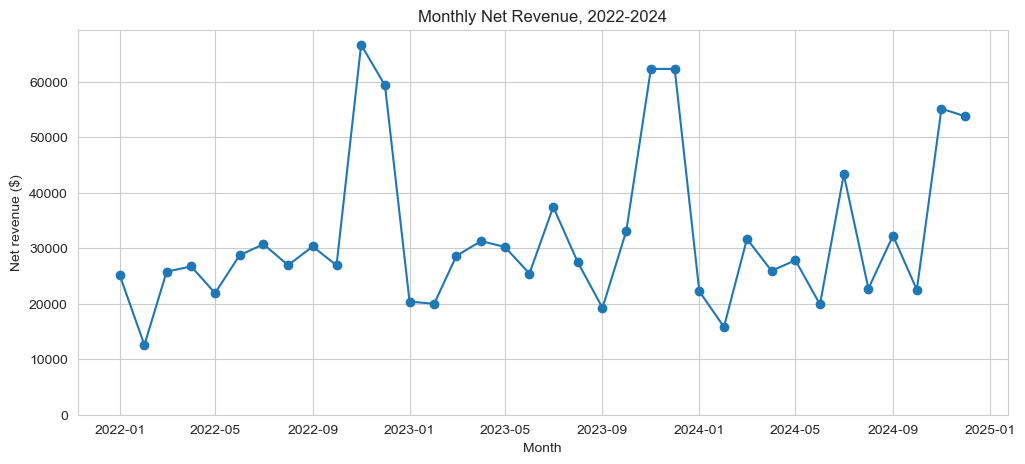

In [51]:
# Monthly Net Revenue

plt.figure(figsize=(12, 5))
plt.plot(monthly.index, monthly.values, marker='o')
plt.title('Monthly Net Revenue, 2022-2024')
plt.xlabel('Month')
plt.ylabel('Net revenue ($)')
plt.ylim(0)
plt.show()

**Findings:**
- Strong holiday seasonality: Nov/Dec run roughly double a normal month, every year
- No real growth 2022-2024 overall; year-over-year swings (+4.2% in 2023, -6.2% in 2024) are within normal variation, not a confirmed trend
- Jan/Feb are a reliable low point each year, a potential opportunity for promotions.

## Q6: Are all regions growing at the same rate? Is it a demand problem or a fulfillment/experience problem?

In [54]:
yearly = df.groupby('Order_Year')['Net_Revenue'].sum().round(0)
print(yearly)
print((yearly.pct_change() * 100).round(1))

holiday = df[df['Order_Month'].isin([11, 12])].groupby('Order_Year')['Net_Revenue'].sum()
print((holiday / yearly * 100).round(1))

Order_Year
2022    381567.0
2023    397630.0
2024    372933.0
Name: Net_Revenue, dtype: float64
Order_Year
2022    NaN
2023    4.2
2024   -6.2
Name: Net_Revenue, dtype: float64
Order_Year
2022    33.0
2023    31.3
2024    29.2
Name: Net_Revenue, dtype: float64


In [55]:
# Additional Cleaning Step

df['Marketing_Channel'] = df['Marketing_Channel'].replace('Unknown', np.nan)

for col in ['Customer_Name', 'City', 'Product_Name']:
    df[col] = df[col].str.strip()

print(df['Marketing_Channel'].value_counts(dropna=False))
print(df['City'].nunique(), df['Product_Name'].nunique())

Marketing_Channel
Organic Search     1357
Social Media       1145
Paid Search        1079
Email Marketing     861
Referral            626
Direct              582
Affiliate           302
NaN                 248
Name: count, dtype: int64
30 136


In [56]:
df.to_csv(r'C:\Trend Mart Analysis\retail_sales_clean.csv', index=False)

In [57]:
df.shape

(6200, 38)

In [58]:
df.columns

Index(['Order_ID', 'Order_Date', 'Ship_Date', 'Customer_ID', 'Customer_Name',
       'Email', 'Age', 'Gender', 'Customer_Segment', 'City', 'State',
       'Country', 'Product_ID', 'Product_Name', 'Category', 'Sub_Category',
       'Unit_Price', 'Cost_Price', 'Quantity', 'Discount_Percent',
       'Shipping_Cost', 'Payment_Method', 'Marketing_Channel', 'Order_Status',
       'Review_Rating', 'Discount_Missing', 'Revenue', 'Total_Cost', 'Profit',
       'Profit_Margin_%', 'Region', 'Order_Year', 'Order_Month',
       'Order_Quarter', 'Order_YearMonth', 'Delivery_Days', 'Order_Date_Raw',
       'Net_Revenue'],
      dtype='object')

In [59]:
# Net Revenue By Region & Year

region_year = df.pivot_table(index='Region', columns='Order_Year', values='Net_Revenue', aggfunc='sum').round(0)
print(region_year)

Order_Year      2022      2023      2024
Region                                  
Midwest      74625.0   85054.0   78328.0
Northeast    32538.0   41138.0   37591.0
South       135007.0  134059.0  116803.0
West        139396.0  137378.0  140212.0


In [60]:
print((region_year.pct_change(axis=1) * 100).round(1))

Order_Year  2022  2023  2024
Region                      
Midwest      NaN  14.0  -7.9
Northeast    NaN  26.4  -8.6
South        NaN  -0.7 -12.9
West         NaN  -1.4   2.1


In [61]:
print((region_year[2024] - region_year[2023]).round(0))

Region
Midwest      -6726.0
Northeast    -3547.0
South       -17256.0
West          2834.0
dtype: float64


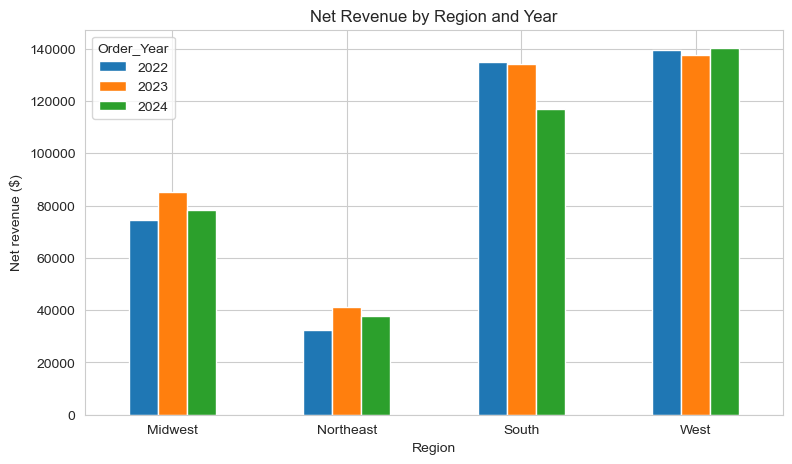

In [62]:
region_year.plot(kind='bar', figsize=(9, 5))
plt.title('Net Revenue by Region and Year')
plt.xlabel('Region')
plt.ylabel('Net revenue ($)')
plt.xticks(rotation=0)
plt.show()

**Findings:**
- West and South together make up ~70% of total revenue; Northeast is smallest (~9%)
- West has stayed flat and steady for 3 years; Midwest and Northeast both rose in 2023 then dipped in 2024
- South's 2024 dip (-$17.3K) is the largest, but it's a small enough gap relative to normal swings that it isn't a confirmed trend, worth monitoring,     not presenting as solved
- Conclusion: no region shows a proven demand or fulfillment problem.

## Q3 & Q4: Which channels have disproportionately high return rates? Is there a specific category + channel combination driving outsized returns?

In [65]:
df['Is_Returned'] = (df['Order_Status'] == 'Returned').astype(int)
print(round(df['Is_Returned'].mean() * 100, 1))

10.1


In [66]:
rate = df.pivot_table(index='Category', columns='Marketing_Channel', values='Is_Returned', aggfunc='mean') * 100


In [67]:
counts = df.pivot_table(index='Category', columns='Marketing_Channel', values='Is_Returned', aggfunc='count')

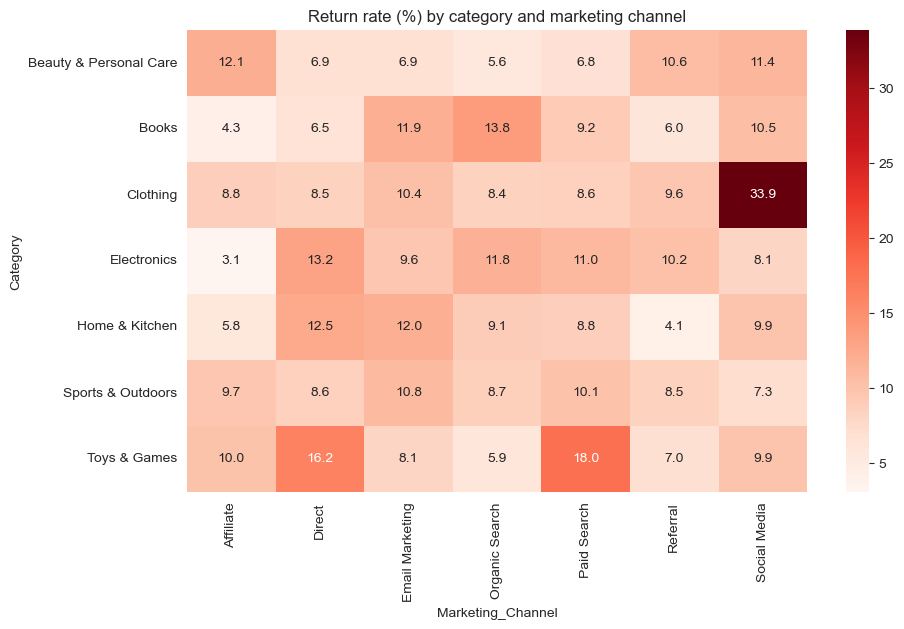

Marketing_Channel       Affiliate  Direct  Email Marketing  Organic Search  \
Category                                                                     
Beauty & Personal Care         33      72              102             161   
Books                          46      77              118             167   
Clothing                       68     117              144             262   
Electronics                    32      76              136             228   
Home & Kitchen                 52      96              142             209   
Sports & Outdoors              31      70              120             161   
Toys & Games                   40      74               99             169   

Marketing_Channel       Paid Search  Referral  Social Media  
Category                                                     
Beauty & Personal Care          147        85           149  
Books                           130        67           152  
Clothing                        187       114    

In [68]:
plt.figure(figsize=(10, 6))
sns.heatmap(rate.round(1), annot=True, fmt='.1f', cmap='Reds')
plt.title('Return rate (%) by category and marketing channel')
plt.show()
print(counts)

**Findings:**
- Company-wide return rate: 10.1%
- Clothing x Social Media = 33.9% returns, more than 3x the company average, backed by a solid 189 orders, not a small-sample fluke
- Social Media is the highest-return channel overall (13.5%), but only modestly, the real story is specific to Clothing, not Social Media in general
- ~64 of the company's 628 total returns (about 10%) trace to this one category-channel combination

## Q3 (continued): Are channels risky on their own, or only in combination with certain categories? Does the same pattern appear in cancellations?

Marketing_Channel
Social Media       13.5
Direct             10.3
Email Marketing    10.1
Paid Search        10.1
Organic Search      9.1
Referral            8.0
Affiliate           7.6
Name: Is_Returned, dtype: float64


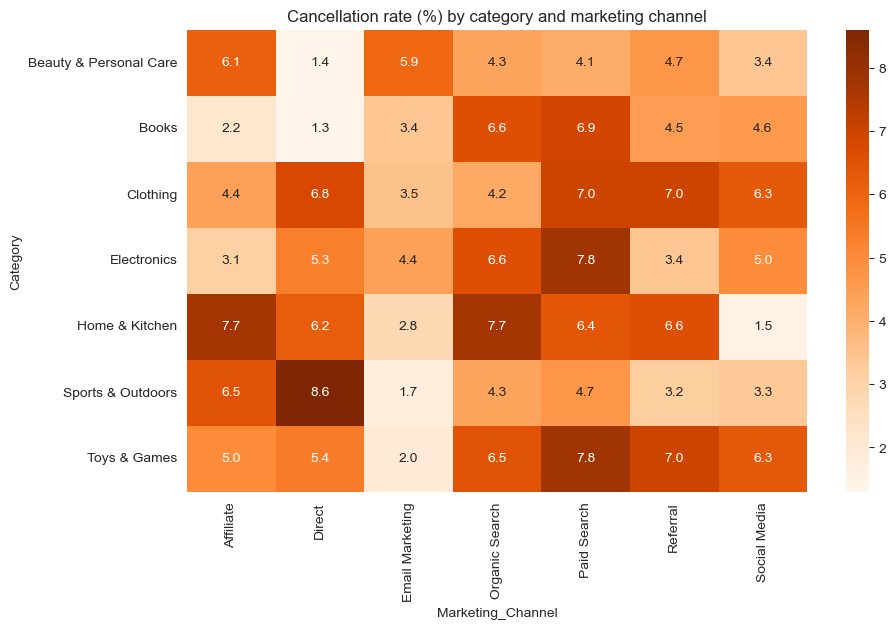

In [71]:
print(df.groupby('Marketing_Channel')['Is_Returned'].mean().mul(100).round(1).sort_values(ascending=False))

df['Is_Cancelled'] = (df['Order_Status'] == 'Cancelled').astype(int)
cancel_rate = df.pivot_table(index='Category', columns='Marketing_Channel', values='Is_Cancelled', aggfunc='mean') * 100
plt.figure(figsize=(10, 6))
sns.heatmap(cancel_rate.round(1), annot=True, fmt='.1f', cmap='Oranges')
plt.title('Cancellation rate (%) by category and marketing channel')
plt.show()

In [72]:
df['Is_Cancelled'] = (df['Order_Status'] == 'Cancelled').astype(int)
print(round(df['Is_Cancelled'].mean() * 100, 1))

5.1


**Findings:**
- Overall cancellation rate: 5.1%
- No cell stands out; highest was Sports & Outdoors/Direct at 8.6%, not far enough above normal to trust as a real pattern
- Conclusion: cancellations look like ordinary checkout friction spread evenly across the business, not a specific, fixable issue like the                Clothing/Social Media returns problem

## Q2: Is profit margin holding steady over time, or eroding in specific categories? What would you tell finance?

Order_Year              2022  2023  2024
Category                                
Beauty & Personal Care  42.5  43.0  42.8
Books                   42.7  43.4  42.5
Clothing                43.3  43.8  42.6
Electronics             43.4  43.3  25.0
Home & Kitchen          43.1  43.1  42.8
Sports & Outdoors       43.4  43.3  43.8
Toys & Games            43.0  43.4  42.8


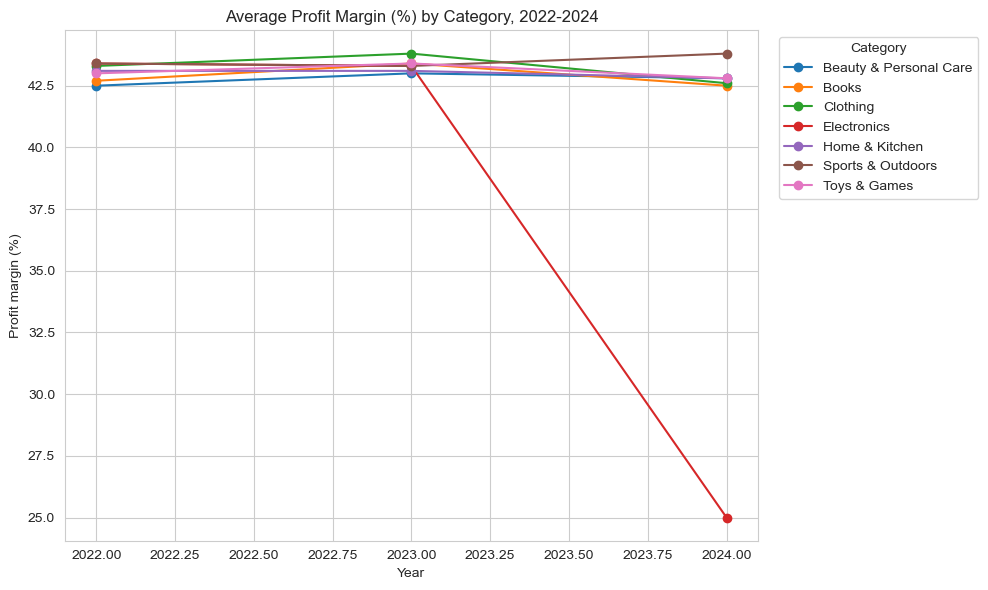

In [75]:
margin_year = df.pivot_table(index='Category', columns='Order_Year', values='Profit_Margin_%', aggfunc='mean').round(1)
print(margin_year)

margin_year.T.plot(figsize=(10, 6), marker='o')
plt.title('Average Profit Margin (%) by Category, 2022-2024')
plt.xlabel('Year')
plt.ylabel('Profit margin (%)')
plt.legend(title='Category', bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [76]:
elec = df[df['Category'] == 'Electronics'].copy()
elec['Cost_Ratio'] = elec['Cost_Price'] / elec['Unit_Price']
print(elec.groupby('Order_Year')['Cost_Ratio'].mean().round(3))

Order_Year
2022    0.532
2023    0.538
2024    0.702
Name: Cost_Ratio, dtype: float64


In [77]:
margin_2023 = 43.3
margin_2024 = 25.0

revenue_2024 = df.loc[(df['Category'] == 'Electronics') & (df['Order_Year'] == 2024), 'Revenue'].sum()

lost_profit = revenue_2024 * (margin_2023 - margin_2024) / 100
print(round(lost_profit))

34820


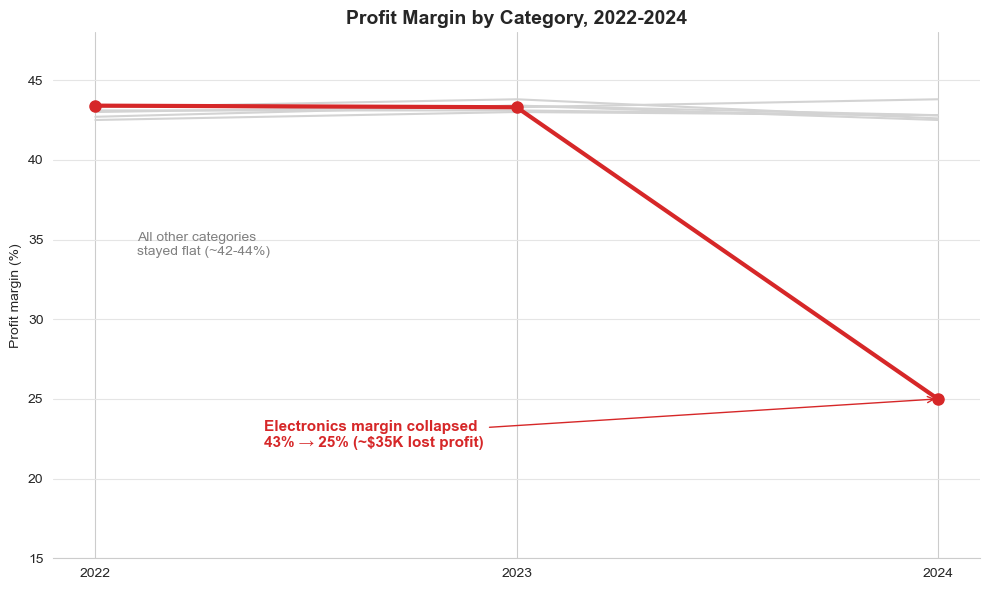

In [78]:
plt.figure(figsize=(10, 6))

years = margin_year.columns

for cat in margin_year.index:
    if cat == 'Electronics':
        continue
    plt.plot(years, margin_year.loc[cat], color='lightgray', linewidth=1.5, zorder=1)

plt.plot(years, margin_year.loc['Electronics'], color='#d62728', linewidth=3, marker='o', markersize=8, zorder=3, label='Electronics')

plt.annotate('All other categories\nstayed flat (~42-44%)',
             xy=(2023, 43), xytext=(2022.1, 34),
             fontsize=10, color='gray')

plt.annotate('Electronics margin collapsed\n43% → 25% (~$35K lost profit)',
             xy=(2024, margin_year.loc['Electronics', 2024]), xytext=(2022.4, 22),
             fontsize=11, color='#d62728', fontweight='bold',
             arrowprops=dict(arrowstyle='->', color='#d62728'))

plt.title('Profit Margin by Category, 2022-2024', fontsize=14, fontweight='bold')
plt.ylabel('Profit margin (%)')
plt.xlabel('')
plt.xticks(years)
plt.ylim(15, 48)

ax = plt.gca()
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.yaxis.grid(True, color='#e5e5e5', linewidth=0.8)
ax.set_axisbelow(True)
plt.tick_params(left=False, bottom=False)

plt.tight_layout()
plt.show()

**Findings:**
- 6 of 7 categories held steady margin (~42-44%) across all 3 years
- Electronics margin collapsed from 43.3% (2023) to 25.0% (2024)
- Root cause: Electronics' cost-of-goods as a share of price jumped from ~53% to ~70% in 2024; selling prices didn't adjust
- Estimated impact: ~$35,000 in lost profit in 2024 alone

## Q1: Which categories and regions are driving revenue and profit, and which are quietly losing the company money once cost and returns are accounted for?
# By Categories

In [81]:
df['Net_Profit'] = df['Profit'].where(~df['Order_Status'].isin(['Returned', 'Cancelled']), -df['Total_Cost'])

summary = df.groupby('Category').agg(
    Revenue=('Revenue', 'sum'),
    Net_Revenue=('Net_Revenue', 'sum'),
    Profit=('Profit', 'sum'),
    Net_Profit=('Net_Profit', 'sum')
).round(0)
summary

,Revenue,Net_Revenue,Profit,Net_Profit
Category,,,,
Beauty & Personal Care,52909.0,45254.0,21947.0,14744.0
Books,32918.0,28385.0,13682.0,9212.0
Clothing,110838.0,88642.0,46017.0,24427.0
Electronics,587098.0,498991.0,210670.0,126067.0
Home & Kitchen,296114.0,255208.0,120679.0,82081.0
Sports & Outdoors,229632.0,199401.0,93576.0,64293.0
Toys & Games,43300.0,36249.0,18077.0,11262.0


In [82]:
summary['Net_Margin_%'] = (summary['Net_Profit'] / summary['Net_Revenue'] * 100).round(1)
print(summary.sort_values('Net_Profit'))

                         Revenue  Net_Revenue    Profit  Net_Profit  \
Category                                                              
Books                    32918.0      28385.0   13682.0      9212.0   
Toys & Games             43300.0      36249.0   18077.0     11262.0   
Beauty & Personal Care   52909.0      45254.0   21947.0     14744.0   
Clothing                110838.0      88642.0   46017.0     24427.0   
Sports & Outdoors       229632.0     199401.0   93576.0     64293.0   
Home & Kitchen          296114.0     255208.0  120679.0     82081.0   
Electronics             587098.0     498991.0  210670.0    126067.0   

                        Net_Margin_%  
Category                              
Books                           32.5  
Toys & Games                    31.1  
Beauty & Personal Care          32.6  
Clothing                        27.6  
Sports & Outdoors               32.2  
Home & Kitchen                  32.2  
Electronics                     25.3  


# By Region

In [84]:
region_summary = df.groupby('Region').agg(
    Revenue=('Revenue', 'sum'),
    Net_Revenue=('Net_Revenue', 'sum'),
    Net_Profit=('Net_Profit', 'sum')
).round(0)
region_summary['Net_Margin_%'] = (region_summary['Net_Profit'] / region_summary['Net_Revenue'] * 100).round(1)
print(region_summary.sort_values('Net_Profit'))

            Revenue  Net_Revenue  Net_Profit  Net_Margin_%
Region                                                    
Northeast  127911.0     111267.0     34430.0          30.9
Midwest    285929.0     238007.0     65978.0          27.7
South      449773.0     385869.0    111151.0          28.8
West       489194.0     416986.0    120528.0          28.9


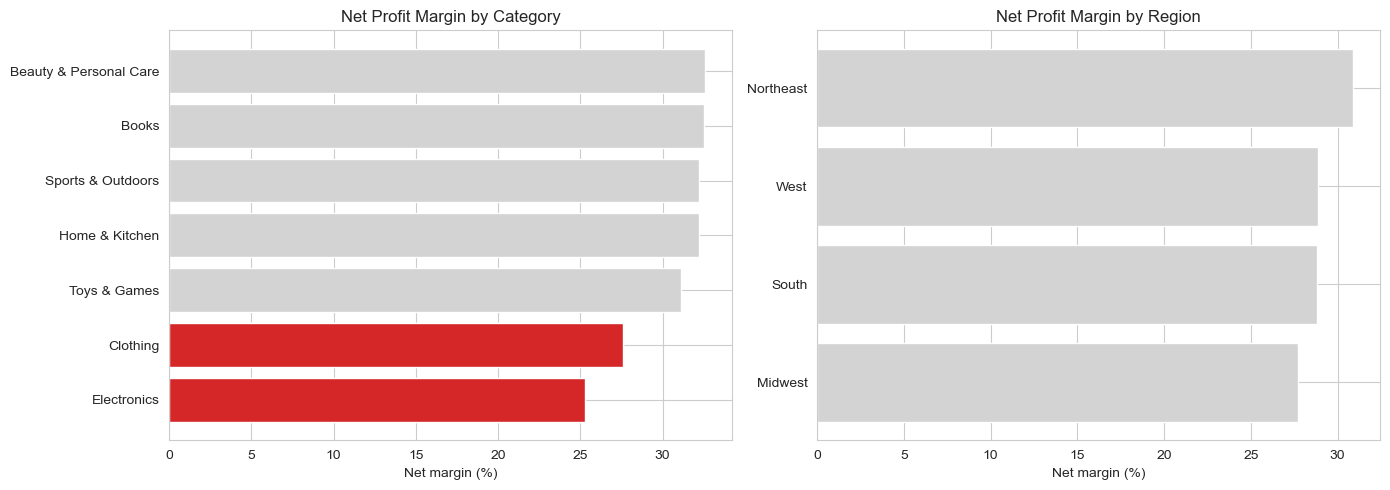

In [85]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

cat_sorted = summary.sort_values('Net_Margin_%')
axes[0].barh(cat_sorted.index, cat_sorted['Net_Margin_%'], color='lightgray')
axes[0].barh(['Electronics', 'Clothing'], cat_sorted.loc[['Electronics', 'Clothing'], 'Net_Margin_%'], color='#d62728')
axes[0].set_title('Net Profit Margin by Category')
axes[0].set_xlabel('Net margin (%)')

reg_sorted = region_summary.sort_values('Net_Margin_%')
axes[1].barh(reg_sorted.index, reg_sorted['Net_Margin_%'], color='lightgray')
axes[1].set_title('Net Profit Margin by Region')
axes[1].set_xlabel('Net margin (%)')

plt.tight_layout()
plt.show()

**Findings:**
- No category is losing money once returns/cancellations are treated as real losses; all 7 remain net-profitable
- Margin is uneven across categories: the chart shows 5 categories clustered close together (31-33% net margin), while Electronics (25.3%) and Clothing (27.6%) visibly break away from that cluster
- Electronics and Clothing being the two weakest margins confirms, from a different angle, the problems already found in Q2 and Q4
- Regional margins show no equivalent pattern, the region chart stays uniformly gray with no standout bar, all 4 regions sit close together        (27.7%-30.9%)
- Revenue is concentrated in West and South (~76% combined), but since their margins are normal, that's a concentration risk, not a profitability problem

## Q7: Is there a relationship between discounting and profitability? Are deep discounts driving incremental revenue, or just eroding margin?

                  Orders  Avg_Revenue  Avg_Margin
Discount_Percent                                 
0.00                3560        228.4        45.8
0.05                 814        236.4        42.7
0.10                 704        209.8        39.5
0.15                 530        193.3        36.1
0.20                 359        194.4        31.9
0.25                 131        152.5        28.4
0.30                 102        150.5        22.5


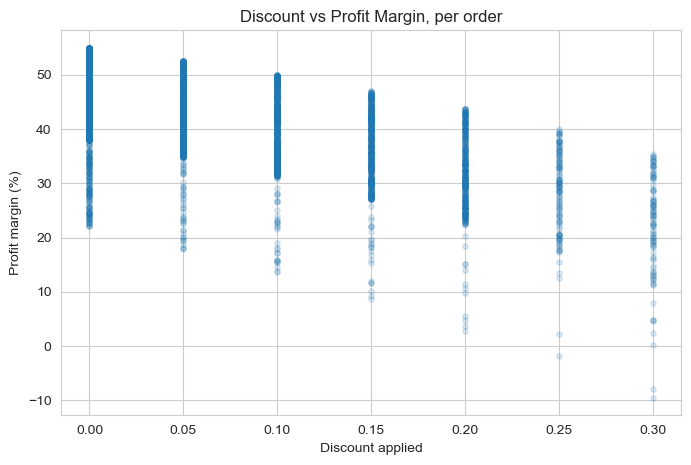

In [87]:
disc_summary = df.groupby('Discount_Percent').agg(
    Orders=('Order_ID', 'count'),
    Avg_Revenue=('Revenue', 'mean'),
    Avg_Margin=('Profit_Margin_%', 'mean')
).round(1)
print(disc_summary)

plt.figure(figsize=(8, 5))
plt.scatter(df['Discount_Percent'], df['Profit_Margin_%'], alpha=0.15, s=15)
plt.xlabel('Discount applied')
plt.ylabel('Profit margin (%)')
plt.title('Discount vs Profit Margin, per order')
plt.show()

**Findings:**
- Profit margin declines steadily and consistently as discount increases, from 45.8% (no discount) down to 22.5% (30% discount)
- Average order value does NOT increase with deeper discounts, it actually decreases ($228 -> $150), so discounts show no evidence of driving bigger      purchases
- Discounting appears to be eroding margin without a clear offsetting benefit in order size

## Q5: How does average order value and order frequency differ across Consumer, Corporate, and Home Office segments, and what does that imply for how each should be marketed to?

In [89]:
segment_summary = df.groupby('Customer_Segment').agg(
    Orders=('Order_ID', 'count'),
    Unique_Customers=('Customer_ID', 'nunique'),
    Avg_Order_Value=('Revenue', 'mean'),
    Total_Revenue=('Revenue', 'sum')
).round(1)
segment_summary['Orders_Per_Customer'] = (segment_summary['Orders'] / segment_summary['Unique_Customers']).round(2)
print(segment_summary)

                  Orders  Unique_Customers  Avg_Order_Value  Total_Revenue  \
Customer_Segment                                                             
Consumer            3816               955            219.1       830653.8   
Corporate           1453               385            222.6       322376.2   
Home Office          931               227            216.2       199777.8   

                  Orders_Per_Customer  
Customer_Segment                       
Consumer                         4.00  
Corporate                        3.77  
Home Office                      4.10  


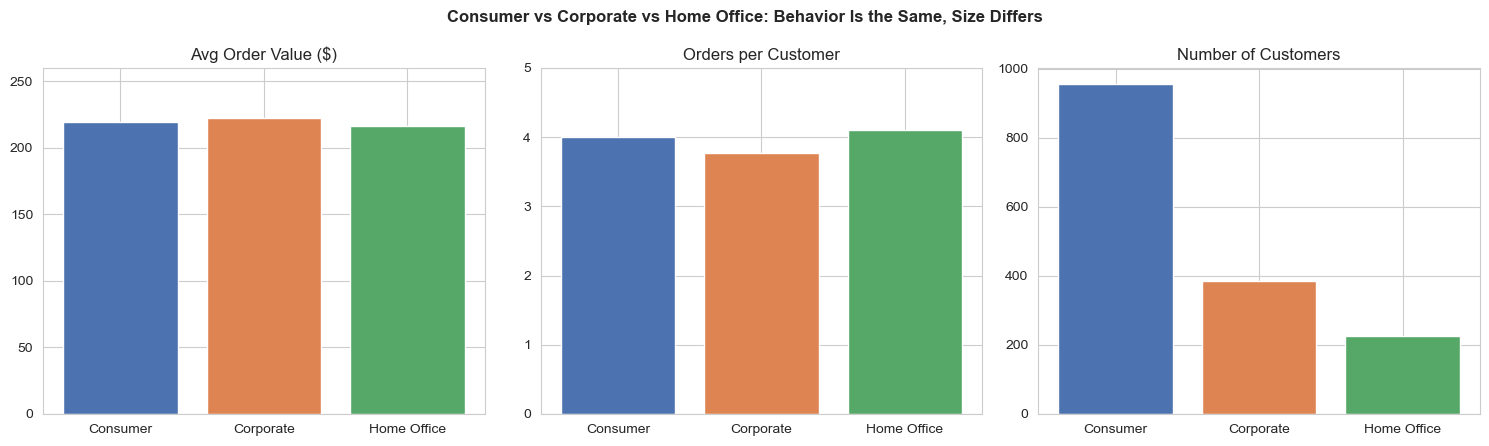

In [173]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

seg_order = ['Consumer', 'Corporate', 'Home Office']
seg_colors = ['#4C72B0', '#DD8452', '#55A868']  # blue, orange, green

axes[0].bar(seg_order, segment_summary.loc[seg_order, 'Avg_Order_Value'], color=seg_colors)
axes[0].set_title('Avg Order Value ($)')
axes[0].set_ylim(0, 260)

axes[1].bar(seg_order, segment_summary.loc[seg_order, 'Orders_Per_Customer'], color=seg_colors)
axes[1].set_title('Orders per Customer')
axes[1].set_ylim(0, 5)

axes[2].bar(seg_order, segment_summary.loc[seg_order, 'Unique_Customers'], color=seg_colors)
axes[2].set_title('Number of Customers')

fig.suptitle('Consumer vs Corporate vs Home Office: Behavior Is the Same, Size Differs', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

**Findings:**
- The chart shows average order value and order frequency are nearly flat across all three segments (~$216-223 AOV, ~3.8-4.1 orders per customer), the bars sit at almost the same height in both charts
- The only chart where the bars differ meaningfully is customer count, Consumer has far more customers (~955) than Corporate (~385) or Home Office (~227). The segments differ in size, not in how they shop
- Conclusion: Customer_Segment alone isn't a useful basis for differentiated marketing strategy in this data; the business would need a different variable (category, channel, or timing) to meaningfully tailor messaging by segment

## Q8: What does the review-rating data tell us about product/category satisfaction, and does low satisfaction line up with high returns?

In [91]:
review_summary = df.groupby('Category').agg(
    Avg_Rating=('Review_Rating', 'mean'),
    Reviews=('Review_Rating', 'count'),
    Return_Rate=('Is_Returned', 'mean')
).round(2)
review_summary['Return_Rate'] = (review_summary['Return_Rate'] * 100).round(1)
print(review_summary.sort_values('Avg_Rating'))

                        Avg_Rating  Reviews  Return_Rate
Category                                                
Books                         3.86      476         10.0
Beauty & Personal Care        3.87      451          8.0
Sports & Outdoors             3.89      497          9.0
Home & Kitchen                3.92      615          9.0
Clothing                      3.94      617         13.0
Toys & Games                  3.94      427         10.0
Electronics                   3.96      511         10.0


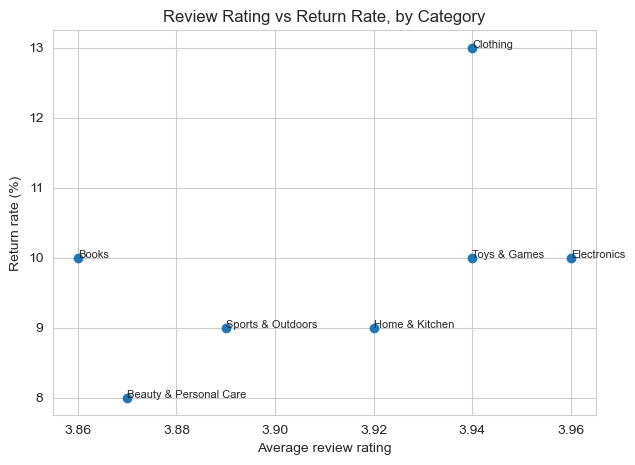

In [92]:
plt.figure(figsize=(7, 5))
plt.scatter(review_summary['Avg_Rating'], review_summary['Return_Rate'])
for cat in review_summary.index:
    plt.annotate(cat, (review_summary.loc[cat, 'Avg_Rating'], review_summary.loc[cat, 'Return_Rate']), fontsize=8)
plt.xlabel('Average review rating')
plt.ylabel('Return rate (%)')
plt.title('Review Rating vs Return Rate, by Category')
plt.show()

**Findings:**
- All categories rate 3.86-3.96, tightly clustered, no meaningful spread
- No relationship between rating and return rate; Clothing has one of the highest ratings (3.94) despite having the highest return rate (13%)
- Conclusion: this confirms the Clothing/Social Media returns problem (Q4) is not a product satisfaction issue, customers who keep their orders rate them well. The problem is specific to how those orders are acquired, not the product itself

In [175]:
df.to_csv(r'C:\Trend Mart Analysis\retail_sales_clean.csv', index=False)
print(df.shape)

(6200, 41)
